# Breast Cancer Diagnosis - Part II: Clustering and Dimensionality Reduction
This notebook covers clustering analysis and dimensionality reduction (PCA) based on the Breast Cancer Wisconsin dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
columns = ['ID', 'Diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
df = pd.read_csv(url, header=None, names=columns)

df['Diagnosis'] = LabelEncoder().fit_transform(df['Diagnosis'])  # M=1, B=0
df.drop(columns=['ID'], inplace=True)

X = df.drop('Diagnosis', axis=1)
y = df['Diagnosis']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [3]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(f"Explained variance ratio (2 PCs): {pca.explained_variance_ratio_}")


Explained variance ratio (2 PCs): [0.44272026 0.18971182]


In [4]:
kmeans = KMeans(n_clusters=2, random_state=42)
clusters_kmeans = kmeans.fit_predict(X_pca)
sil_kmeans = silhouette_score(X_pca, clusters_kmeans)
print(f"KMeans Silhouette Score: {sil_kmeans:.4f}")


KMeans Silhouette Score: 0.5085


c:\Users\pedro\anaconda3\envs\wust-ml-lab-1\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [5]:
agnes = AgglomerativeClustering(n_clusters=2)
clusters_agnes = agnes.fit_predict(X_pca)
sil_agnes = silhouette_score(X_pca, clusters_agnes)
print(f"Agglomerative Clustering Silhouette Score: {sil_agnes:.4f}")


Agglomerative Clustering Silhouette Score: 0.5046


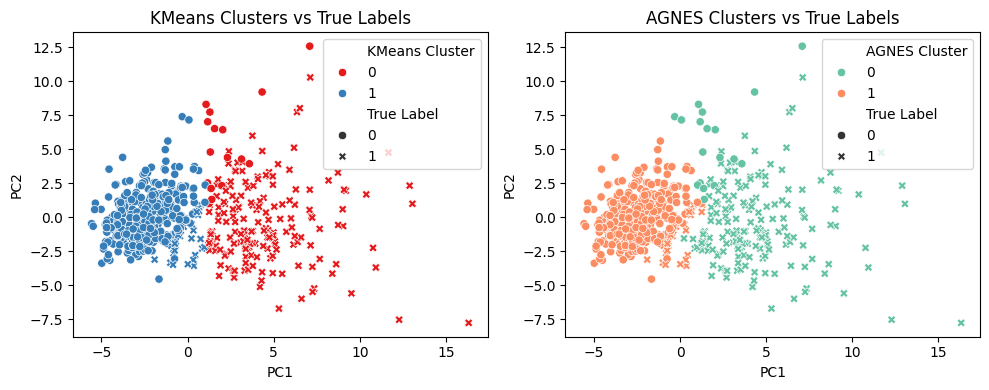

In [6]:
# Visual comparison of clusters vs. true diagnosis
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['True Label'] = y
pca_df['KMeans Cluster'] = clusters_kmeans
pca_df['AGNES Cluster'] = clusters_agnes

# Plot KMeans clusters
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='KMeans Cluster', style='True Label', palette='Set1')
plt.title('KMeans Clusters vs True Labels')

# Plot AGNES clusters
plt.subplot(1, 2, 2)
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='AGNES Cluster', style='True Label', palette='Set2')
plt.title('AGNES Clusters vs True Labels')
plt.tight_layout()
plt.show()


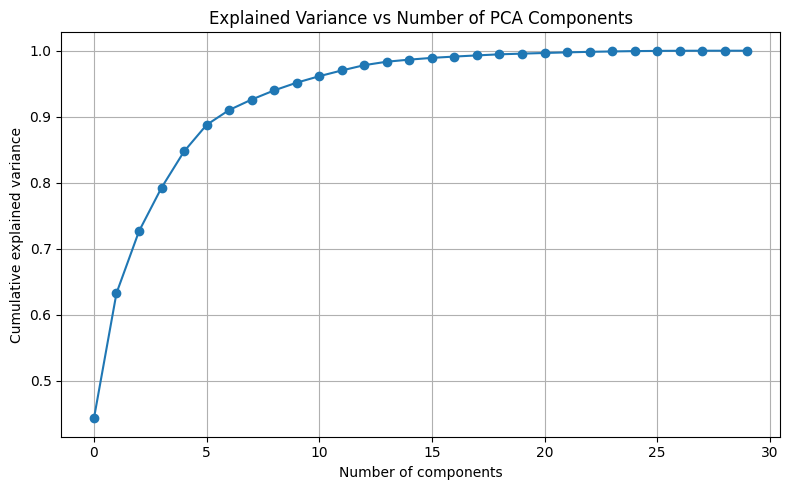

In [7]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# PCA for full component analysis
pca_full = PCA()
pca_full.fit(X_scaled)

plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Explained Variance vs Number of PCA Components')
plt.grid(True)
plt.tight_layout()
plt.show()


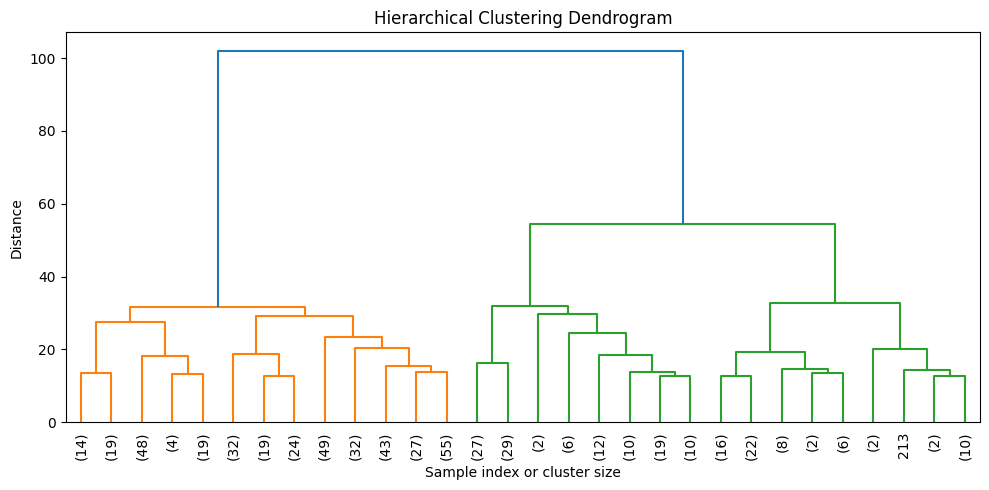

In [8]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10.)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample index or cluster size')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()


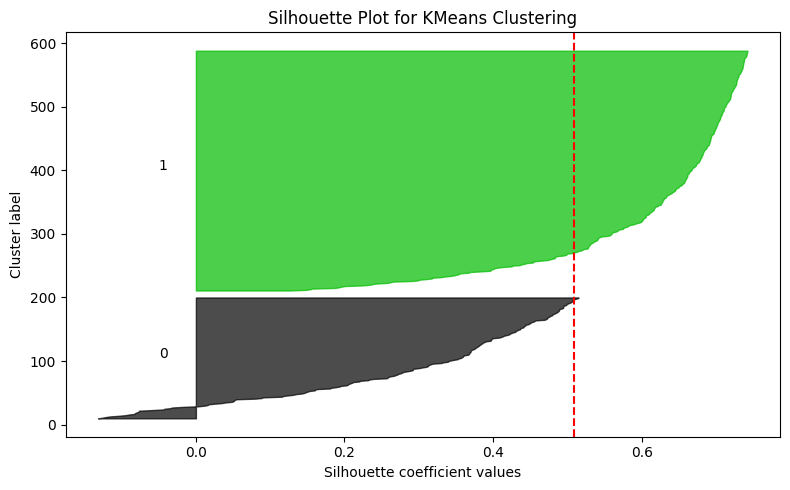

In [9]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

sil_vals = silhouette_samples(X_pca, clusters_kmeans)

plt.figure(figsize=(8, 5))
y_lower = 10
for i in np.unique(clusters_kmeans):
    ith_cluster_sil_vals = sil_vals[clusters_kmeans == i]
    ith_cluster_sil_vals.sort()
    size_cluster_i = ith_cluster_sil_vals.shape[0]
    y_upper = y_lower + size_cluster_i
    color = cm.nipy_spectral(float(i) / 2)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_vals, facecolor=color, edgecolor=color, alpha=0.7)
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10
plt.title("Silhouette Plot for KMeans Clustering")
plt.xlabel("Silhouette coefficient values")
plt.ylabel("Cluster label")
plt.axvline(x=sil_vals.mean(), color="red", linestyle="--")
plt.tight_layout()
plt.show()
